# Gibbs Sampling and LDA

**Seong Cho** · ACME Volume 3

**Lab objective:** write a Gibbs sampler for a Bayesian model of exam scores, then a collapsed Gibbs sampler for latent Dirichlet allocation (LDA), and use it to find the topics in Ronald Reagan's addresses.

<sub>Lab specification from the *Volume 3* lab materials of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the course's lab notebook. Solutions are my own.</sub>

In [1]:
import numpy as np
from scipy.special import gammaln
from scipy.stats import norm
from scipy.stats import invgamma
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

## Problem 1: A Gibbs sampler for exam scores

> **Problem 1.** Implement a Gibbs sampler for the exam scores problem (using the data in `examscores.npy`).
> Test your sampler with priors $\nu=80$, $\tau^{2} = 16$, $\alpha = 3$, and $\beta = 50$, collecting $1000$ samples.
> Plot your samples of $\mu$ and your samples of $\sigma^{2}$.

In [2]:
def gibbs(y, nu, tau2, alpha, beta, n_samples):
    """Gibbs sampler for the exam scores problem, assuming the
    following likelihood and priors.
        y_i    ~ N(mu, sigma2),
        mu     ~ N(nu, tau2),
        sigma2 ~ IG(alpha, beta),

    Parameters:
        y ((N,) ndarray): the exam scores.
        nu (float): The prior mean parameter for mu.
        tau2 (float > 0): The prior variance parameter for mu.
        alpha (float > 0): The prior alpha parameter for sigma2.
        beta (float < 0): The prior beta parameter for sigma2.
        n_samples (int): the number of samples to draw.

    Returns:
        ((n_samples, 2) ndarray): The mu and sigma2 samples (as columns).
    """
    N = len(y)
    mu = norm.rvs(nu, scale=np.sqrt(tau2))
    sigma = invgamma.rvs(alpha, scale=beta)
    alpha_star = alpha + N/2
    mu_samples = [mu]
    sig_samples = [sigma]
    for _ in range(n_samples):
        sig_star = 1/(1/tau2 + N/sigma)
        mu_star = sig_star * (nu/tau2 + (1/sigma)*np.sum(y))
        beta_star = beta + 1/2*np.sum((y - mu)**2)
        mu = norm.rvs(mu_star, scale=np.sqrt(sig_star))
        sigma = invgamma.rvs(alpha_star, scale=beta_star)
        mu_samples.append(mu)
        sig_samples.append(sigma)
    return mu_samples, sig_samples

In [3]:
np.random.seed(0)
exam_scores = np.load("examscores.npy")
mus, sigs = gibbs(exam_scores, 80, 16, 3, 50, 1000)

The samples of $\mu$ and of $\sigma^2$, in the order they were drawn (this plot is added; my original notebook went straight to the density estimates in Problem 2):

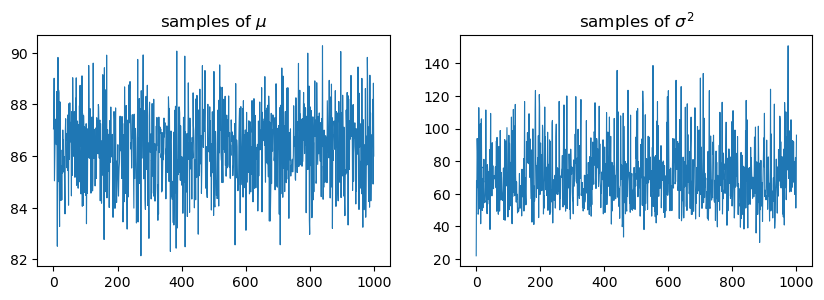

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(mus, lw=.8)
ax[0].set_title(r"samples of $\mu$")
ax[1].plot(sigs, lw=.8)
ax[1].set_title(r"samples of $\sigma^2$")
plt.show()

## Problem 2: Posterior and posterior predictive densities

> **Problem 2.** Plot the kernel density estimators for the posterior distributions of $\mu$ and $\sigma^2$.
>
> Next, use your samples of $\mu$ and $\sigma^2$ to draw samples from the posterior predictive distribution.
> Plot the kernel density estimator of your sampled scores.

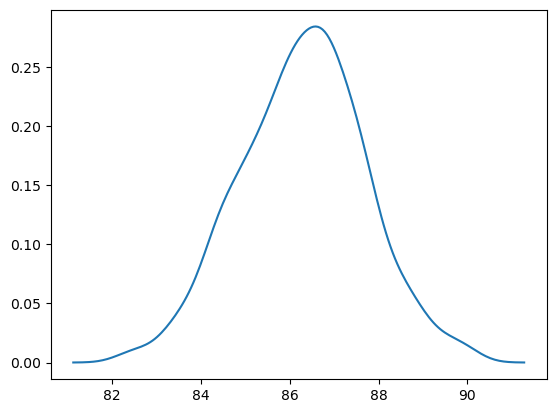

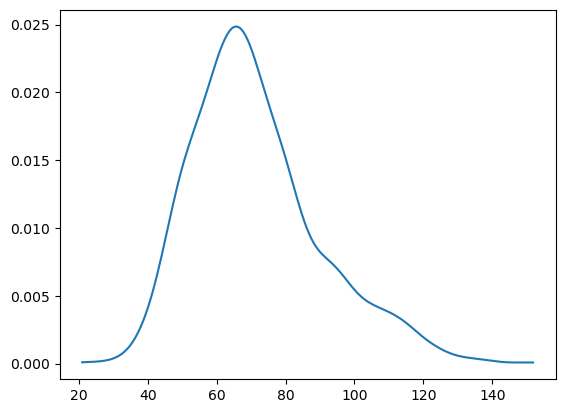

In [5]:
mu_kernel = gaussian_kde(mus)
x1 = np.linspace(min(mus) - 1, max(mus) + 1, 200)
plt.plot(x1, mu_kernel(x1))
plt.show()
sig_kernel = gaussian_kde(sigs)
x2 = np.linspace(min(sigs) - 1, max(sigs) + 1, 200)
plt.plot(x2, sig_kernel(x2))
plt.show()

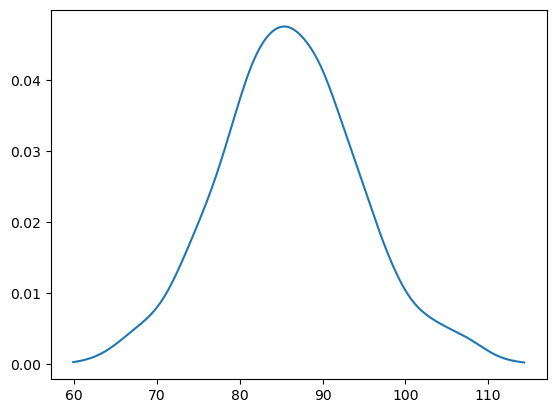

In [6]:
np.random.seed(0)
scores = []
for mu, sigma in zip(mus, sigs):
    score = norm.rvs(mu, scale=np.sqrt(sigma))
    scores.append(score)
score_kernel = gaussian_kde(scores)
x = np.linspace(min(scores) - 1, max(scores) + 1, 200)
plt.plot(x, score_kernel(x))
plt.show()

Independent check: the posterior density of $(\mu, \sigma^2)$ is proportional to the product of the likelihood and the priors, so it can be evaluated on a fine grid and summed numerically. The sampled posterior means match the grid values, and the kernel density estimates follow the grid marginals (dashed).

posterior mean of mu:     samples 86.299, grid 86.312
posterior mean of sigma2: samples 71.339, grid 71.500


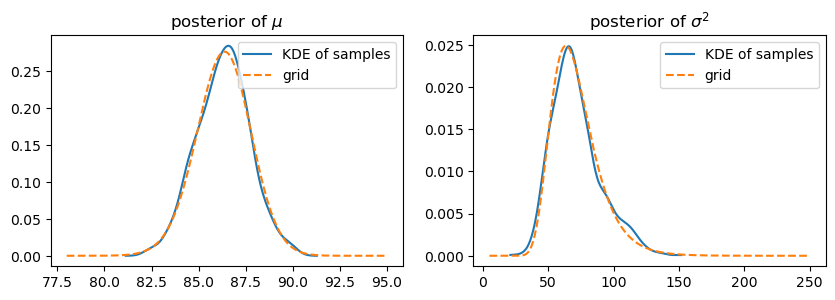

In [7]:
mu_g = np.linspace(78, 95, 681)
s2_g = np.linspace(5, 250, 981)
M, S2 = np.meshgrid(mu_g, s2_g, indexing="ij")
logp = (norm.logpdf(exam_scores[:, None, None], M, np.sqrt(S2)).sum(axis=0)
        + norm.logpdf(M, 80, np.sqrt(16)) + invgamma.logpdf(S2, 3, scale=50))
P = np.exp(logp - logp.max())
P /= P.sum()
mu_mean, s2_mean = (P*M).sum(), (P*S2).sum()
print("posterior mean of mu:     samples {:.3f}, grid {:.3f}".format(np.mean(mus), mu_mean))
print("posterior mean of sigma2: samples {:.3f}, grid {:.3f}".format(np.mean(sigs), s2_mean))
assert abs(np.mean(mus) - mu_mean) < 0.5
assert abs(np.mean(sigs) - s2_mean) / s2_mean < 0.05

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(x1, mu_kernel(x1), label="KDE of samples")
ax[0].plot(mu_g, P.sum(axis=1) / (mu_g[1] - mu_g[0]), "--", label="grid")
ax[0].set_title(r"posterior of $\mu$")
ax[0].legend()
ax[1].plot(x2, sig_kernel(x2), label="KDE of samples")
ax[1].plot(s2_g, P.sum(axis=0) / (s2_g[1] - s2_g[0]), "--", label="grid")
ax[1].set_title(r"posterior of $\sigma^2$")
ax[1].legend()
plt.show()

## Problems 3–5: The `LDACGS` class

Problems 3, 4 and 5 each complete one method of the same `LDACGS` class, so the class is in one cell after the three statements.

> **Problem 3.** Implement `LDACGS.initialize()`.
> By randomly assigning initial topics, fill in the count matrices and topic assignment dictionary.
> In this method, you will initialize the count matrices (among other things).
>
> To be explicit, you will need to initialize $nmz$, $nzw$, and $nz$ to be zero arrays of the correct size.
> Then, in the second for loop, you will assign z to be a random integer in the correct range of topics.
> In the increment step, you need to figure out the correct indices to increment by one for each of the three arrays.
> Finally, assign $topics$ as given.

> **Problem 4.** Complete `LDACGS._sweep()`, which needs to iterate through each word of each document.
> It should call `LDACGS._conditional()` to get the conditional distribution at each iteration.
>
> Note that the first part of this method will undo what `LDACGS.initialize()` did.
> Then we will use the conditional distribution (instead of the uniform distribution we used previously) to pick a more accurate topic assignment.
> Finally, the latter part repeats what we did in `LDACGS.initialize()`, but does so using this more accurate topic assignment.

> **Problem 5.** Complete `LDACGS.sample()`.
> The argument `filename` is the name and location of a .txt file, where each line is considered a document.
> The corpus is built by `LDACGS.buildCorpus()`, and stopwords are removed (if argument `stopwords` is provided).
> Burn in the Gibbs sampler, computing and saving the log-likelihood with the method `_loglikelihood()`.
> After the burn in, iterate further, accumulating your count matrices, by adding `nzw` and `nmz` to `total_nzw` and `total_nmz` respectively, where you only add every `sample_rate`th iteration.
> Also save each log-likelihood.

In [8]:
class LDACGS:
    """Do LDA with Gibbs Sampling."""

    def __init__(self, n_topics, alpha=0.1, beta=0.1):
        """Initialize system parameters."""
        self.n_topics = n_topics
        self.alpha = alpha
        self.beta = beta

    def buildCorpus(self, filename, stopwords_file=None):
        """Read the given filename and build the vocabulary."""
        with open(filename, 'r') as infile:
            doclines = [line.rstrip().lower().split(' ') for line in infile]
        n_docs = len(doclines)
        self.vocab = list({v for doc in doclines for v in doc})
        if stopwords_file:
            with open(stopwords_file, 'r') as stopfile:
                stops = stopfile.read().split()
            self.vocab = [x for x in self.vocab if x not in stops]
            self.vocab.sort()
        self.documents = []
        for i in range(n_docs):
            self.documents.append({})
            for j in range(len(doclines[i])):
                if doclines[i][j] in self.vocab:
                    self.documents[i][j] = self.vocab.index(doclines[i][j])

    def initialize(self):
        """Initialize the three count matrices."""
        self.n_words = len(self.vocab)
        self.n_docs = len(self.documents)
        
        # Initialize the three count matrices.
        # The (i,j) entry of self.nmz is the number of words in document i assigned to topic j.
        self.nmz = np.zeros((self.n_docs, self.n_topics))
        # The (i,j) entry of self.nzw is the number of times term j is assigned to topic i.
        self.nzw = np.zeros((self.n_topics, self.n_words))
        # The (i)-th entry is the number of times topic i is assigned in the corpus.
        self.nz = np.zeros(self.n_topics)

        # Initialize the topic assignment dictionary.
        self.topics = {} # key-value pairs of form (m,i):z

        for m in range(self.n_docs):
            for i in self.documents[m]:
                z = np.random.randint(0, self.n_topics)
                w = self.documents[m][i]
                self.nmz[m,z] += 1
                self.nzw[z,w] += 1
                self.nz[z] += 1
                self.topics[(m,i)] = z

    def sample(self,filename, burnin=100, sample_rate=10, n_samples=10, stopwords_file=None):
        self.buildCorpus(filename, stopwords_file)
        self.initialize()
        self.total_nzw = np.zeros((self.n_topics, self.n_words))
        self.total_nmz = np.zeros((self.n_docs, self.n_topics))
        self.logprobs = np.zeros(burnin + sample_rate*n_samples)
        ll = []
        for i in range(burnin):
            # Sweep and store log likelihood.
            self._sweep()
            ll.append(self._loglikelihood())
        for i in range(n_samples*sample_rate):
            # Sweep and store log likelihood
            self._sweep()
            ll.append(self._loglikelihood())
            if not i % sample_rate:
                # accumulate counts
                self.total_nzw += self.nzw
                self.total_nmz += self.nmz
        return ll
    
    def phi(self):
        phi = self.total_nzw + self.beta
        self._phi = phi / np.sum(phi, axis=1)[:,np.newaxis]

    def theta(self):
        theta = self.total_nmz + self.alpha
        self._theta = theta / np.sum(theta, axis=1)[:,np.newaxis]

    def topterms(self,n_terms=10):
        self.phi()
        self.theta()
        vec = np.atleast_2d(np.arange(0,self.n_words))
        topics = []
        for k in range(self.n_topics):
            probs = np.atleast_2d(self._phi[k,:])
            mat = np.append(probs,vec,0)
            sind = np.array([mat[:,i] for i in np.argsort(mat[0])]).T
            topics.append([self.vocab[int(sind[1,self.n_words - 1 - i])] for i in range(n_terms)])
        return topics

    def toplines(self,n_lines=5):
        lines = np.zeros((self.n_topics,n_lines))
        for i in range(self.n_topics):
            args = np.argsort(self._theta[:,i]).tolist()
            args.reverse()
            lines[i,:] = np.array(args)[0:n_lines] + 1
        return lines

    def _removeStopwords(self, stopwords):
        return [x for x in self.vocab if x not in stopwords]

    def _conditional(self, m, w):
        dist = (self.nmz[m,:] + self.alpha) * (self.nzw[:,w] + self.beta) / (self.nz + self.beta*self.n_words)
        return dist / np.sum(dist)

    def _sweep(self):
        for m in range(self.n_docs):
            for i in self.documents[m]:
                # Retrieve vocab index for i-th word in document m.
                # Retrieve topic assignment for i-th word in document m.
                # Decrement count matrices.
                # Get conditional distribution.
                # Sample new topic assignment.
                # Increment count matrices.
                # Store new topic assignment.
                w = self.documents[m][i]
                z = self.topics[(m,i)]
                self.nmz[m,z]-=1
                self.nzw[z,w]-=1
                self.nz[z]-=1
                z = np.random.choice(self.n_topics, p=self._conditional(m,w))
                self.nmz[m,z]+=1
                self.nzw[z,w]+=1
                self.nz[z]+=1
                self.topics[(m,i)] = z

    def _loglikelihood(self):
        lik = 0

        for z in range(self.n_topics):
            lik += np.sum(gammaln(self.nzw[z,:] + self.beta)) - gammaln(np.sum(self.nzw[z,:] + self.beta))
            lik -= self.n_words * gammaln(self.beta) - gammaln(self.n_words*self.beta)

        for m in range(self.n_docs):
            lik += np.sum(gammaln(self.nmz[m,:] + self.alpha)) - gammaln(np.sum(self.nmz[m,:] + self.alpha))
            lik -= self.n_topics * gammaln(self.alpha) - gammaln(self.n_topics*self.alpha)

        return lik

Checks on the count matrices, after `initialize()` and again after one `_sweep()`: every word of the corpus has one topic, the three count arrays agree with each other, with the document lengths and with the word frequencies, no count is negative, and the conditional distributions are probability vectors.

In [9]:
def check_counts(lda):
    words = np.array([w for doc in lda.documents for w in doc.values()])
    assert len(lda.topics) == len(words) == lda.nmz.sum() == lda.nzw.sum() == lda.nz.sum()
    assert np.array_equal(lda.nmz.sum(axis=1), [len(doc) for doc in lda.documents])
    assert np.array_equal(lda.nzw.sum(axis=0), np.bincount(words, minlength=lda.n_words))
    assert np.array_equal(lda.nz, lda.nzw.sum(axis=1))
    assert lda.nmz.min() >= 0 and lda.nzw.min() >= 0
    for m in range(lda.n_docs):
        for i, w in lda.documents[m].items():
            assert lda.nmz[m, lda.topics[(m, i)]] > 0 and lda.nzw[lda.topics[(m, i)], w] > 0
    return len(words)

np.random.seed(0)
test = LDACGS(20)
test.buildCorpus("reagan.txt", stopwords_file="stopwords.txt")
stops = set(open("stopwords.txt").read().split())
assert not stops & set(test.vocab)
test.initialize()
print(test.n_docs, "documents,", test.n_words, "terms,", check_counts(test), "words")
before = dict(test.topics)
test._sweep()
check_counts(test)
print("topic assignments changed by one sweep:", sum(before[k] != test.topics[k] for k in before))
assert np.isclose(test._conditional(0, test.documents[0][next(iter(test.documents[0]))]).sum(), 1)

557 documents, 6186 terms, 17723 words
topic assignments changed by one sweep: 15964


## Problem 6: Topics in Reagan's addresses

> **Problem 6.** Create an `LDACGS` object with $20$ topics, letting $\alpha$ and $\beta$ be the default values.
> Run the Gibbs sampler, with a burn in of $100$ iterations, accumulating $10$ samples, only keeping the results of every $10$th sweep.
> Use `stopwords.txt` as the stopwords file.
>
> Plot the log-likelihoods. How long did it take to burn in?

In [10]:
np.random.seed(0)
lda = LDACGS(20)
ll = lda.sample("reagan.txt", stopwords_file="stopwords.txt")

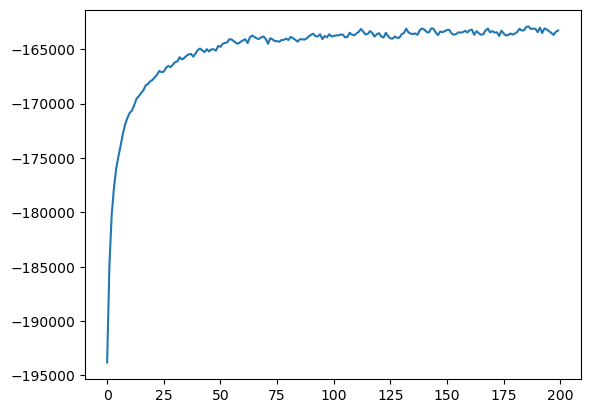

It takes around 25 iterations for it to burn in.


In [11]:
plt.plot(ll)
plt.show()
print("It takes around 25 iterations for it to burn in.")

Check: one log-likelihood per sweep ($100 + 10 \cdot 10 = 200$), the accumulated counts hold exactly $10$ samples of the corpus, and the counts are still consistent at the end.

In [12]:
n_words = check_counts(lda)
print(len(ll), "log-likelihoods; total_nzw sums to", lda.total_nzw.sum(), "=", n_words, "x", lda.total_nzw.sum() / n_words)
assert len(ll) == 200 and lda.total_nzw.sum() == lda.total_nmz.sum() == 10 * n_words

200 log-likelihoods; total_nzw sums to 177230.0 = 17723 x 10.0


## Problem 7: Labeling the topics

> **Problem 7.** Using `topterms()` to examine the topics for Reagan's addresses.
> Come up with labels for each topic.
> If `ntopics=20` and `n=10`, we will get the top $10$ words that represent each of the $20$ topics; for each topic, decide what these ten words jointly represent.

In [13]:
for i,terms in enumerate(lda.topterms()):
    print(i, ":", terms)

0 : ['states', 'united', 'rights', 'time', 'true', 'laws', 'crime', 'women', 'means', 'efforts']
1 : ['bipartisan', 'commission', 'senate', 'hope', 'house', 'leader', 'majority', 'join', 'plan', 'americans']
2 : ['programs', 'federal', 'government', 'social', 'states', 'welfare', 'billion', 'local', 'savings', 'private']
3 : ['tax', 'rate', 'rates', 'inflation', 'interest', 'economic', 'increase', 'program', 'billion', 'cut']
4 : ['--', 'years', '2', 'percent', 'high', 'time', 'ago,', 'interest', 'years,', 'american']
5 : ['mr.', 'speaker,', 'members', 'congress,', 'president,', 'distinguished', 'fellow', 'honored', 'tonight', 'guests,']
6 : ['special', 'unemployment', 'young', 'million', 'highest', 'people', 'drugs.', 'america.', 'people.', 'employment']
7 : ['people', "we're", 'space', "don't", 'americans', 'millions', 'us.', "we've", 'yes,', 'end']
8 : ['life', 'human', 'spirit', 'child', 'dream', 'living', 'now,', 'unborn', 'long', 'born']
9 : ['children', 'families', 'school', 'fu

The sampler is random, so the topics above (from the seeded rerun) come out in a different order, and with somewhat different terms, than in my original run. My labels below were written for the topics of the original run, whose `topterms()` output was:

```text
0 : ['years', 'time', '--', 'rights', 'crime', 'ago', "we've", 'victims', 'long', '2']
1 : ['year', 'ago,', 'trillion', 'debt', 'inflation', 'time,', 'fiscal', 'food', 'late', 'stack']
2 : ['budget', 'spending', 'national', 'deficits', 'deficit', 'growth', 'years', 'meet', 'federal', 'reduce']
3 : ['americans', 'problems', 'millions', "we're", 'yes,', 'us.', 'people.', 'living', 'spirit', 'high']
4 : ["can't", 'rising', 'began', 'years,', 'setting', 'washington', 'tragedy', 'safety.', 'woman', 'franklin']
5 : ['america', '--', 'people', 'american', 'great', 'nation', 'freedom', 'time', 'tonight', 'peace']
6 : ['children', 'families', 'school', 'education', 'community', 'parents', 'and,', 'family', 'child', 'back']
7 : ['god', 'bless', 'you,', 'america.', 'you.', 'drugs.', 'single', 'music', 'personal', 'thing']
8 : ['welfare', 'reform', 'full', 'laws', 'poverty', 'support', 'propose', 'start', 'work', 'fair']
9 : ['tax', 'economic', 'rates', 'interest', '--', 'rate', 'program', 'inflation', 'percent', 'spending']
10 : ['federal', 'regulations', 'growth', 'regulatory', "it's", 'pages', 'order', 'public', 'plan', 'monetary']
11 : ['world', 'soviet', 'freedom', 'defense', 'peace', 'free', 'trade', 'arms', 'security', 'democratic']
12 : ['mr.', 'members', 'speaker,', 'congress,', 'president,', 'distinguished', 'congress', 'fellow', 'tonight', 'honored']
13 : ['federal', 'programs', 'government', 'billion', 'states', 'savings', 'local', 'private', 'social', '--']
14 : ['space', 'develop', 'day', 'build', "we're", 'research', 'make', 'earth.', 'well,', 'technology']
15 : ['state', 'congress', 'union', 'president', 'address', 'session', 'now,', 'joint', '.', 'ronald']
16 : ['jobs', 'work', 'job', 'special', 'program', 'enterprise', 'people', 'unemployment', 'jobs,', 'act']
17 : ['programs', 'social', 'protect', 'life', 'human', 'health', 'safety', 'now,', 'security', 'child']
18 : ['government', 'people', 'federal', 'american', "we're", 'waste', 'time', 'budget', "it's", 'dollars']
19 : ["let's", 'give', 'veto', '43', 'pass', 'balanced', 'congress', 'items', 'work', 'line-item']
```

0: crime rates  
1: economy  
2: government spending  
3: social issues  
4: security  
5: American values  
6: family and home  
7: American life  
8: welfare  
9: economy / tax  
10: regulations  
11: diplomatic relations  
12: government workers  
13: local government  
14: research and technology  
15: president  
16: employment  
17: social security  
18: government spending  
19: bills